# 1. Image Loading & Color Channels
Load the image, convert to RGB and Grayscale, and separate individual R, G, B color channels.

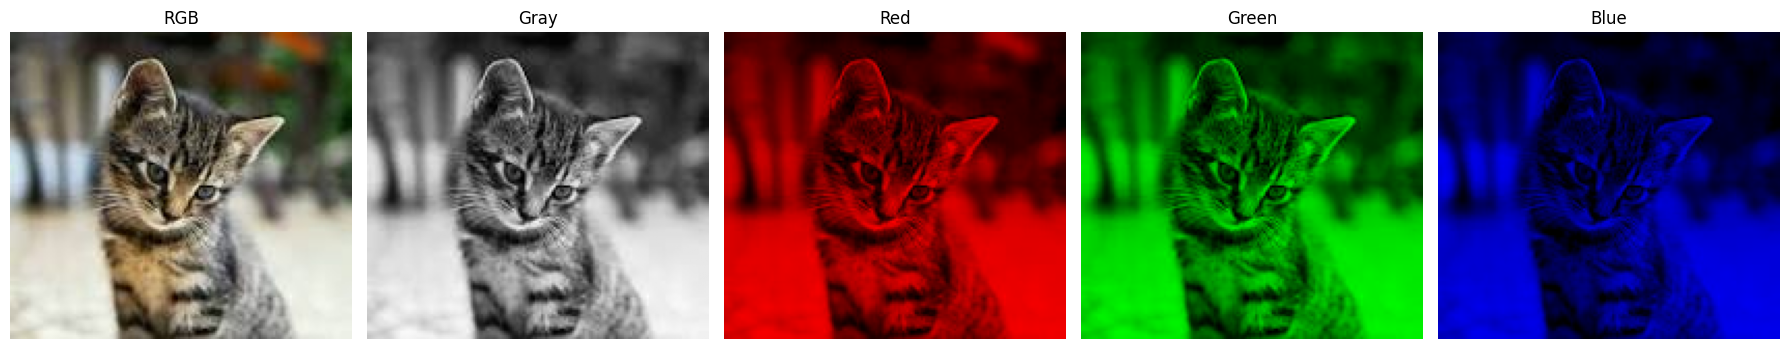

In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# Load image
img = cv.imread("image.jpeg")
if img is None:
    raise FileNotFoundError("Could not load image.jpeg")

# Convert BGR to RGB and Grayscale
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
h, w = img_gray.shape

# Split and reconstruct R, G, B channels
r, g, b = cv.split(img_rgb)
zeros = np.zeros_like(r)
red = cv.merge([r, zeros, zeros])
green = cv.merge([zeros, g, zeros])
blue = cv.merge([zeros, zeros, b])

# Plot results
images = [("RGB", img_rgb), ("Gray", img_gray), ("Red", red), ("Green", green), ("Blue", blue)]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 2. Image Thresholding
Apply Binary, Binary Inverse, Otsu, and Adaptive thresholding on the grayscale image.

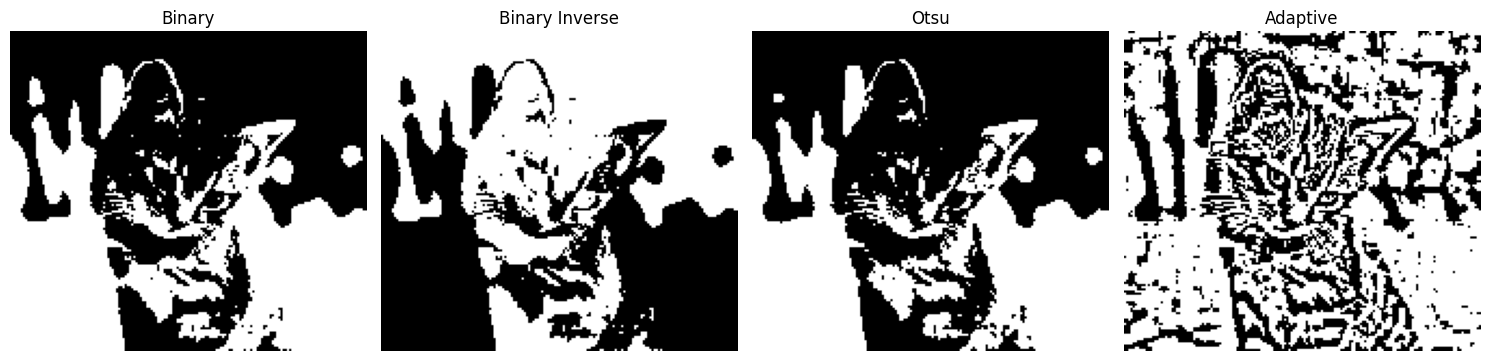

In [2]:
# Global and Otsu thresholding
_, img_bin = cv.threshold(img_gray, 127, 255, cv.THRESH_BINARY)
_, img_bin_inv = cv.threshold(img_gray, 127, 255, cv.THRESH_BINARY_INV)
_, img_otsu = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# Adaptive thresholding
thresh_adaptive = cv.adaptiveThreshold(img_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

# Plot results
images = [("Binary", img_bin), ("Binary Inverse", img_bin_inv), ("Otsu", img_otsu), ("Adaptive", thresh_adaptive)]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 3. Arithmetic & Logical Operations
Perform manual pixel-wise arithmetic (`+`, `-`, `*`, `/`) and bitwise logical (`&`, `|`, `^`, `~`) operations using NumPy.

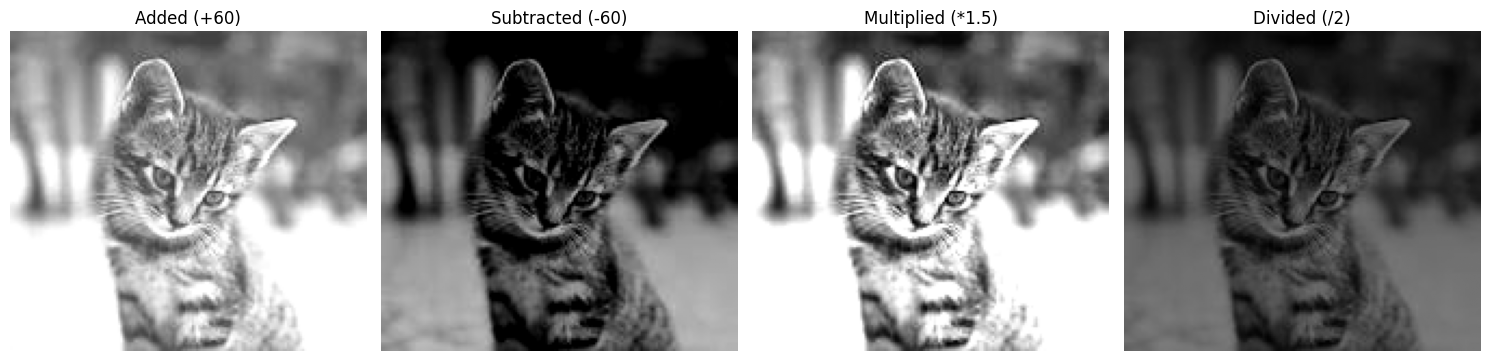

In [3]:
# Arithmetic Operations (clipped to [0, 255] to prevent uint8 overflow)
added = np.clip(img_gray.astype(np.int16) + 60, 0, 255).astype(np.uint8)
subtracted = np.clip(img_gray.astype(np.int16) - 60, 0, 255).astype(np.uint8)
multiplied = np.clip(img_gray.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)
divided = np.clip(img_gray.astype(np.float32) / 2.0, 0, 255).astype(np.uint8)

images = [("Added (+60)", added), ("Subtracted (-60)", subtracted), ("Multiplied (*1.5)", multiplied), ("Divided (/2)", divided)]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

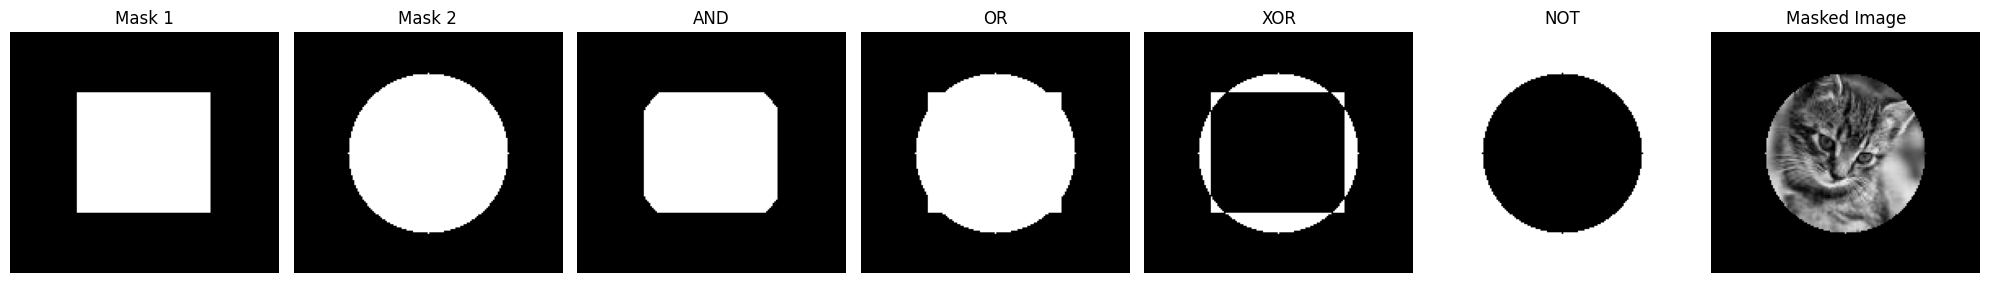

In [4]:
# Create two binary masks (Rectangle and Circle) for Logical Operations
mask1 = np.zeros((h, w), dtype=np.uint8)
mask1[h // 4 : 3 * h // 4, w // 4 : 3 * w // 4] = 255

y, x = np.ogrid[:h, :w]
mask2 = np.where((x - w // 2) ** 2 + (y - h // 2) ** 2 <= (min(h, w) // 3) ** 2, 255, 0).astype(np.uint8)

# Logical Operations using NumPy bitwise operators
bit_and = mask1 & mask2
bit_or = mask1 | mask2
bit_xor = mask1 ^ mask2
bit_not = ~mask2
masked_img = img_gray & mask2  # Apply circular mask to image

images = [("Mask 1", mask1), ("Mask 2", mask2), ("AND", bit_and), ("OR", bit_or), ("XOR", bit_xor), ("NOT", bit_not), ("Masked Image", masked_img)]
fig, axes = plt.subplots(1, 7, figsize=(20, 3.5))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 4. Spatial & Intensity Resolution
Demonstrate spatial downsampling/reconstruction and intensity level quantization.

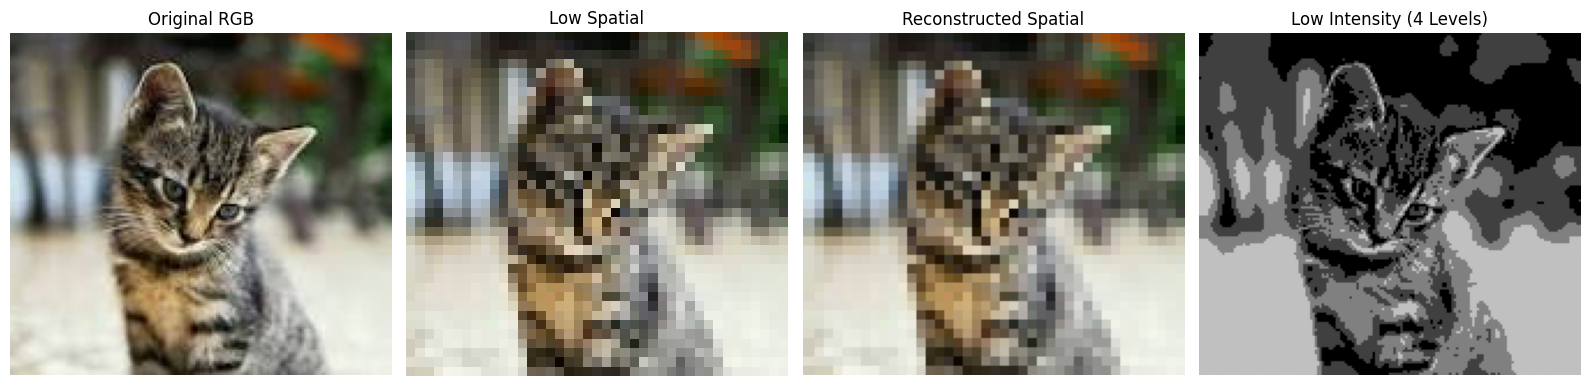

In [5]:
# Spatial resolution (downsample by 4x and reconstruct with nearest neighbor)
low_spatial = cv.resize(img_rgb, (max(1, w // 4), max(1, h // 4)), interpolation=cv.INTER_LINEAR)
reconstructed_spatial = cv.resize(low_spatial, (w, h), interpolation=cv.INTER_NEAREST)

# Intensity resolution (quantize intensity levels)
low_intensity = (img_gray // 64) * 64  # Reduce to 4 intensity levels

images = [("Original RGB", img_rgb), ("Low Spatial", low_spatial), ("Reconstructed Spatial", reconstructed_spatial), ("Low Intensity (4 Levels)", low_intensity)]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None, vmin=0, vmax=255 if image.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 5. Geometric Transformations
Perform zooming, rotation, and translation on the image.

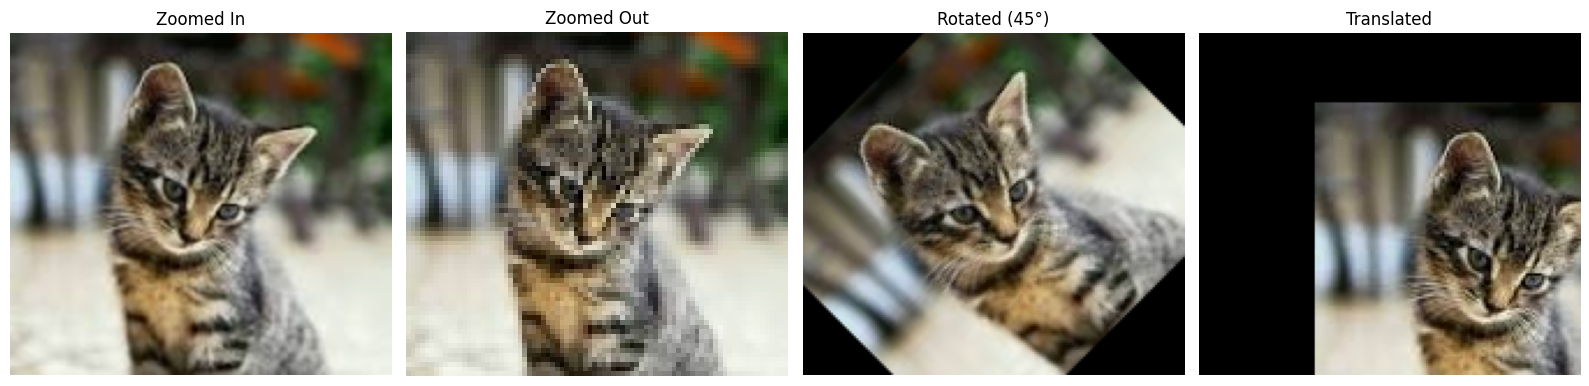

In [6]:
# Zooming in and out
zoomed_in = cv.resize(img_rgb, (w * 2, h * 2), interpolation=cv.INTER_LINEAR)
zoomed_out = cv.resize(img_rgb, (max(1, w // 2), max(1, h // 2)), interpolation=cv.INTER_LINEAR)

# Rotation by 45 degrees around center
M_rot = cv.getRotationMatrix2D((w / 2, h / 2), 45, 1)
rotated = cv.warpAffine(img_rgb, M_rot, (w, h))

# Translation by (tx=50, ty=30)
translation_matrix = np.float32([[1, 0, 50], [0, 1, 30]])
translated = cv.warpAffine(img_rgb, translation_matrix, (w, h))

images = [("Zoomed In", zoomed_in), ("Zoomed Out", zoomed_out), ("Rotated (45°)", rotated), ("Translated", translated)]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 6. Point & Intensity Transformations
Apply Negative, Log, Power-Law (Gamma), Contrast Stretching, Intensity Slicing, and Bit-Plane Slicing.

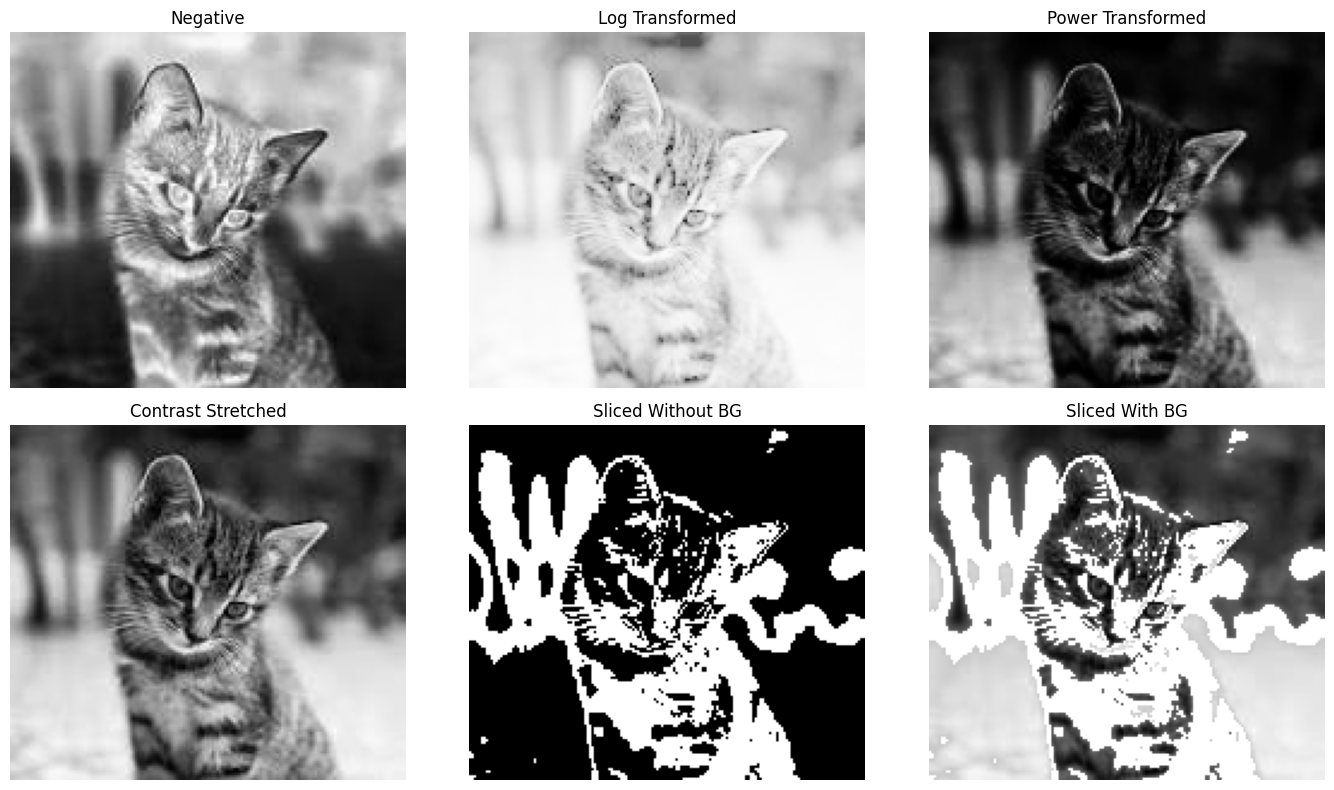

In [7]:
# Image Negative: s = 255 - r
negative = 255 - img_gray

# Log Transformation: s = c * log(1 + r)
c_log = 255 / np.log1p(np.max(img_gray))
log_transformed = np.clip(c_log * np.log1p(img_gray), 0, 255).astype(np.uint8)

# Power-Law (Gamma) Transformation: s = c * r^gamma
power_transformed = np.clip(255 * (img_gray.astype(np.float32) / 255.0) ** 2, 0, 255).astype(np.uint8)

# Contrast Stretching: normalize [min, max] to [0, 255]
img_min, img_max = img_gray.min(), img_gray.max()
contrast_stretched = (
    np.zeros_like(img_gray) if img_max == img_min
    else np.clip((img_gray.astype(np.float32) - img_min) * 255 / (img_max - img_min), 0, 255).astype(np.uint8)
)

# Intensity Level Slicing (highlight range [100, 200])
sliced_without_bg = np.where((img_gray >= 100) & (img_gray <= 200), 255, 0).astype(np.uint8)
sliced_with_bg = np.where((img_gray >= 100) & (img_gray <= 200), 255, img_gray).astype(np.uint8)

images = [
    ("Negative", negative), ("Log Transformed", log_transformed), ("Power Transformed", power_transformed),
    ("Contrast Stretched", contrast_stretched), ("Sliced Without BG", sliced_without_bg), ("Sliced With BG", sliced_with_bg)
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (title, image) in zip(axes.ravel(), images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

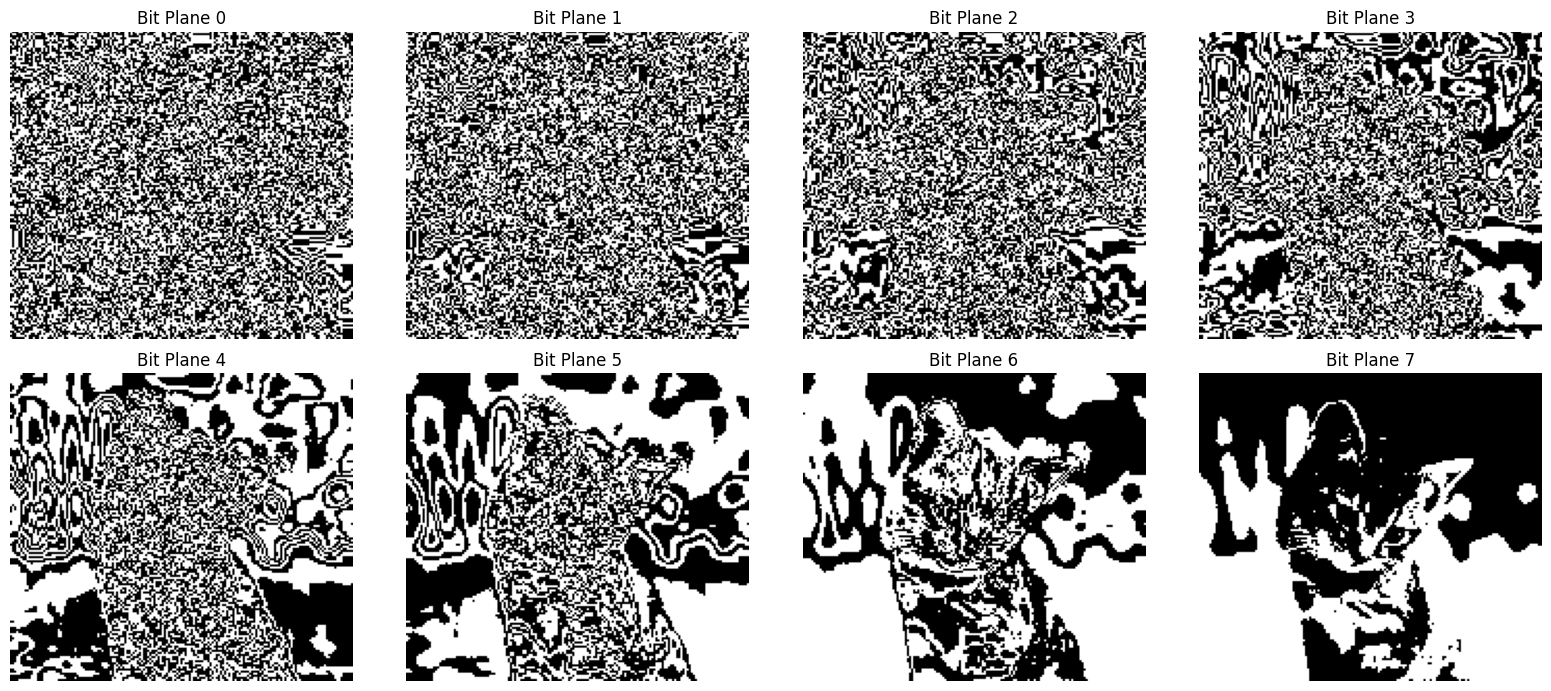

In [8]:
# Bit-Plane Slicing (extract bits 0 to 7)
bitplanes = [(((img_gray >> i) & 1) * 255).astype(np.uint8) for i in range(8)]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(bitplanes[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Bit Plane {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# 7. Histogram Processing
Compute the grayscale histogram and perform manual Histogram Equalization using PDF and CDF.

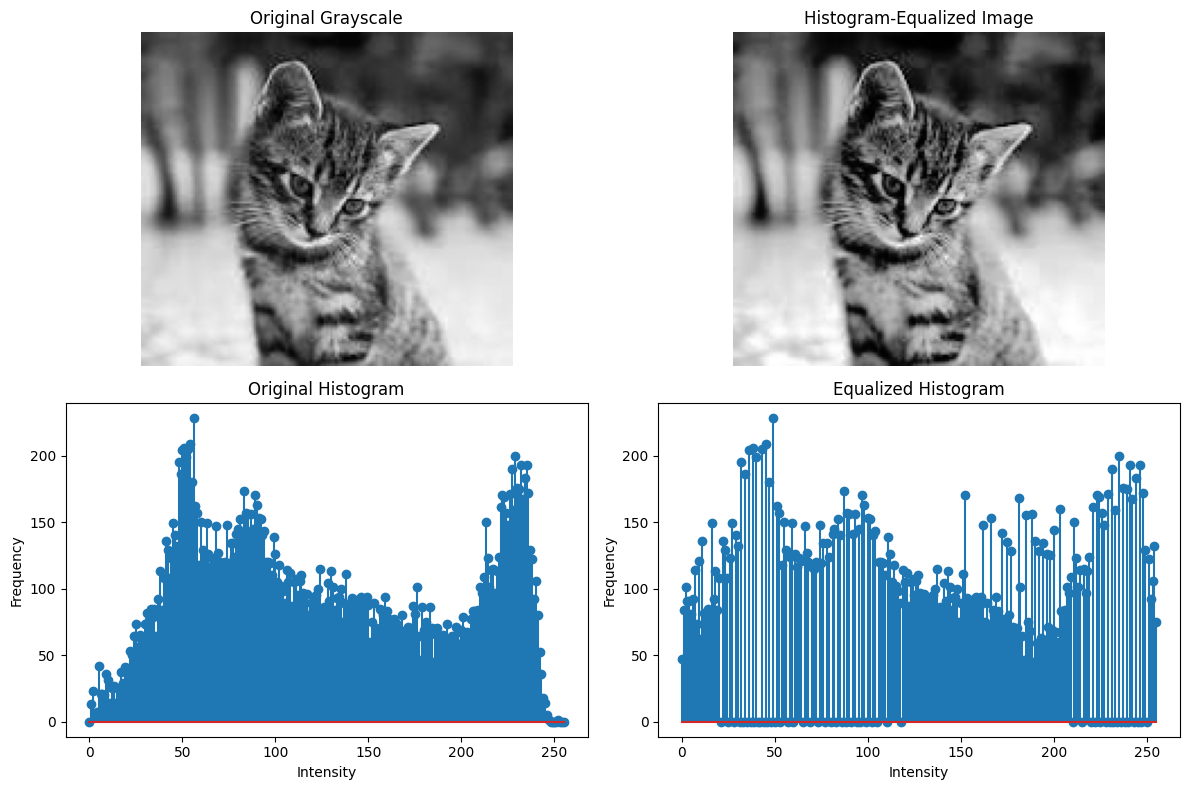

In [22]:
# Compute original histogram
histogram, bin_edges = np.histogram(img_gray.ravel(), bins=256, range=(0, 256))

# Manual Histogram Equalization via PDF and CDF
pdf = histogram / histogram.sum()
cdf = np.cumsum(pdf)
equalized_lut = np.round(255 * cdf).astype(np.uint8)
img_equalized = equalized_lut[img_gray]

# Compute equalized histogram
hist_equalized, equalized_edges = np.histogram(img_equalized.ravel(), bins=256, range=(0, 256))

# Plot Original vs Equalized Image and Histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(img_gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Grayscale")
axes[0, 0].axis("off")

axes[0, 1].imshow(img_equalized, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Histogram-Equalized Image")
axes[0, 1].axis("off")

axes[1, 0].stem(bin_edges[:-1], histogram)
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlabel("Intensity")
axes[1, 0].set_ylabel("Frequency")

axes[1, 1].stem(equalized_edges[:-1], hist_equalized)
axes[1, 1].set_title("Equalized Histogram")
axes[1, 1].set_xlabel("Intensity")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# 8. Spatial Filtering
Implement manual 2D convolution (`apply_kernel`), smoothing filters (Mean, Gaussian), order-statistic filters (Min, Max, Median), and sharpening filters (Laplacian, Sobel).

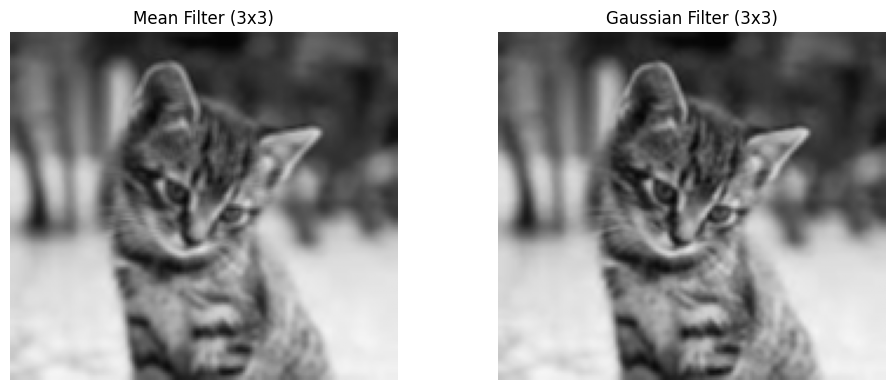

In [25]:
# Manual 2D spatial filtering function
def apply_kernel(kernel, image):
    k_h, k_w = kernel.shape
    i_h, i_w = image.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    padded = np.pad(image.astype(np.float64), ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    filtered = np.empty((i_h, i_w), dtype=np.float64)

    for row in range(i_h):
        for col in range(i_w):
            region = padded[row : row + k_h, col : col + k_w]
            filtered[row, col] = np.sum(region * kernel)
    return filtered

# Manual 3x3 Mean Filter and 3x3 Gaussian Filter
mean_kernel = np.ones((3, 3), dtype=np.float32) / 9
mean_filtered = apply_kernel(mean_kernel, img_gray)

gauss_kernel = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32) / 16
gauss_filtered = apply_kernel(gauss_kernel, img_gray)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(mean_filtered, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Mean Filter (3x3)")
axes[0].axis("off")

axes[1].imshow(gauss_filtered, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Gaussian Filter (3x3)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

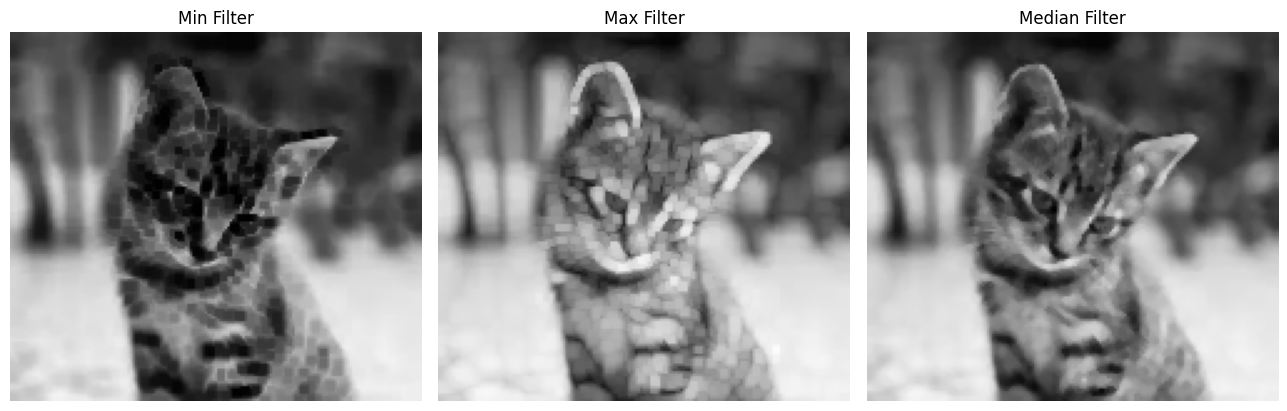

In [11]:
# Manual Order-Statistic Filters: Min, Max, and Median
def min_max_filter(kernel_size, image):
    k_h, k_w = kernel_size
    i_h, i_w = image.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    min_filtered = np.empty_like(image)
    max_filtered = np.empty_like(image)

    for row in range(i_h):
        for col in range(i_w):
            region = padded[row : row + k_h, col : col + k_w]
            min_filtered[row, col] = region.min()
            max_filtered[row, col] = region.max()
    return min_filtered, max_filtered


def median_filter(kernel_size, image):
    k_h, k_w = kernel_size
    i_h, i_w = image.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    filtered = np.empty_like(image)

    for row in range(i_h):
        for col in range(i_w):
            region = padded[row : row + k_h, col : col + k_w]
            filtered[row, col] = np.median(region)
    return filtered

min_filtered_image, max_filtered_image = min_max_filter((3, 3), img_gray)
median_filtered_image = median_filter((3, 3), img_gray)

images = [("Min Filter", min_filtered_image), ("Max Filter", max_filtered_image), ("Median Filter", median_filtered_image)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

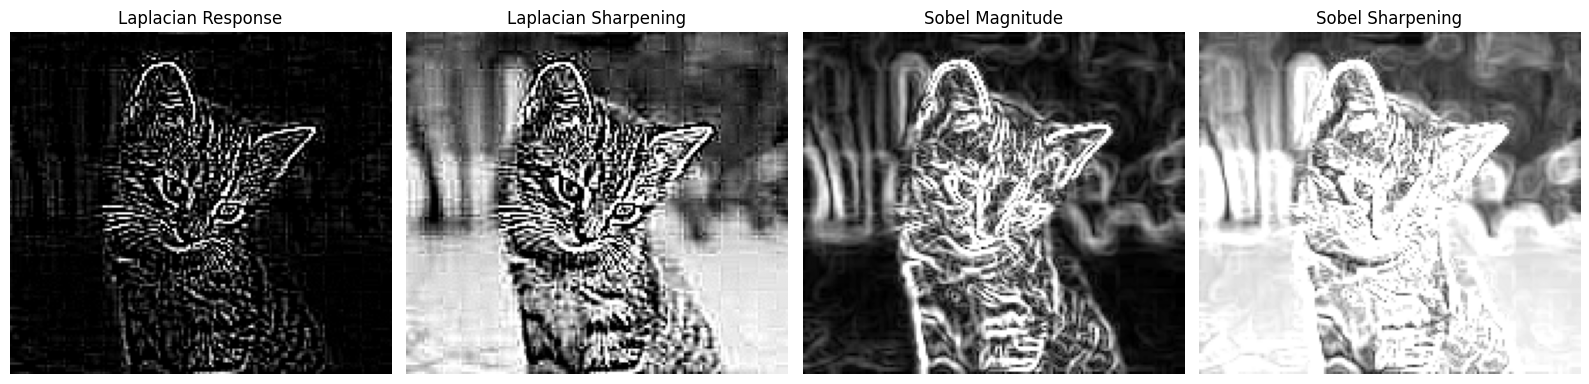

In [26]:
# Laplacian and Sobel Sharpening Filters
laplacian_kernel = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=np.float32)
laplacian_filtered_image = apply_kernel(laplacian_kernel, img_gray)
laplacian_sharpened_img = np.clip(img_gray.astype(np.float64) + laplacian_filtered_image, 0, 255).astype(np.uint8)

sobel_kernel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
sobel_kernel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)
sobel_x_filtered_image = apply_kernel(sobel_kernel_x, img_gray)
sobel_y_filtered_image = apply_kernel(sobel_kernel_y, img_gray)
sobel_filtered_image = np.hypot(sobel_x_filtered_image, sobel_y_filtered_image)
sobel_sharpened_img = np.clip(img_gray.astype(np.float64) + sobel_filtered_image, 0, 255).astype(np.uint8)

images = [
    ("Laplacian Response", np.clip(laplacian_filtered_image, 0, 255)),
    ("Laplacian Sharpening", laplacian_sharpened_img),
    ("Sobel Magnitude", np.clip(sobel_filtered_image, 0, 255)),
    ("Sobel Sharpening", sobel_sharpened_img)
]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 9. Noise Models & Restoration
Add Salt-and-Pepper or Gaussian noise and restore the images using manual Median and Gaussian filters.

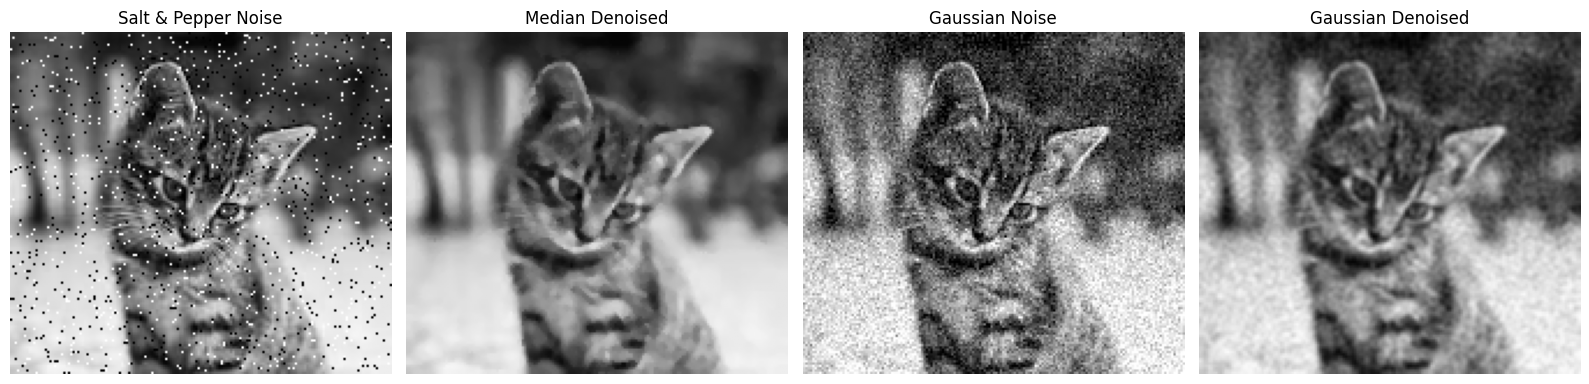

In [ ]:
# Add Salt-and-Pepper noise and restore using manual median_filter
def add_salt_pepper(image, salt_prob, pepper_prob, seed=0):
    noisy_image = image.copy()
    rng = np.random.default_rng(seed)
    total_pixels = image.size
    salt_count = int(total_pixels * salt_prob)
    pepper_count = int(total_pixels * pepper_prob)

    salt_coords = tuple(rng.integers(0, size, salt_count) for size in image.shape)
    pepper_coords = tuple(rng.integers(0, size, pepper_count) for size in image.shape)
    noisy_image[salt_coords] = 255
    noisy_image[pepper_coords] = 0
    return noisy_image

def add_salt_pepper(img, salt_prob=0.05, pepper_prob=0.05):
    noisy = img.copy()

    random = np.random.random(img.shape)

    # Add salt noise (white pixels)
    noisy[random < salt_prob] = 255

    # Add pepper noise (black pixels)
    noisy[random > 1 - pepper_prob] = 0

    return noisy

noisy_img = add_salt_pepper(img_gray, salt_prob=0.05, pepper_prob=0.05)
median_denoised_img = median_filter((3, 3), noisy_img)

# Add Gaussian noise and restore using manual apply_kernel with Gaussian kernel
rng = np.random.default_rng(0)
gauss_noise = rng.normal(0, 25, img_gray.shape).astype(np.float32)
gaussian_noisy_img = np.clip(img_gray.astype(np.float32) + gauss_noise, 0, 255).astype(np.uint8)
restored_gaussian_img = apply_kernel(gauss_kernel, gaussian_noisy_img)

images = [
    ("Salt & Pepper Noise", noisy_img), ("Median Denoised", median_denoised_img),
    ("Gaussian Noise", gaussian_noisy_img), ("Gaussian Denoised", restored_gaussian_img)
]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, image) in zip(axes, images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 10. Frequency-Domain Filtering
Build Ideal, Butterworth, and Gaussian Low-Pass and High-Pass filters in the frequency domain.

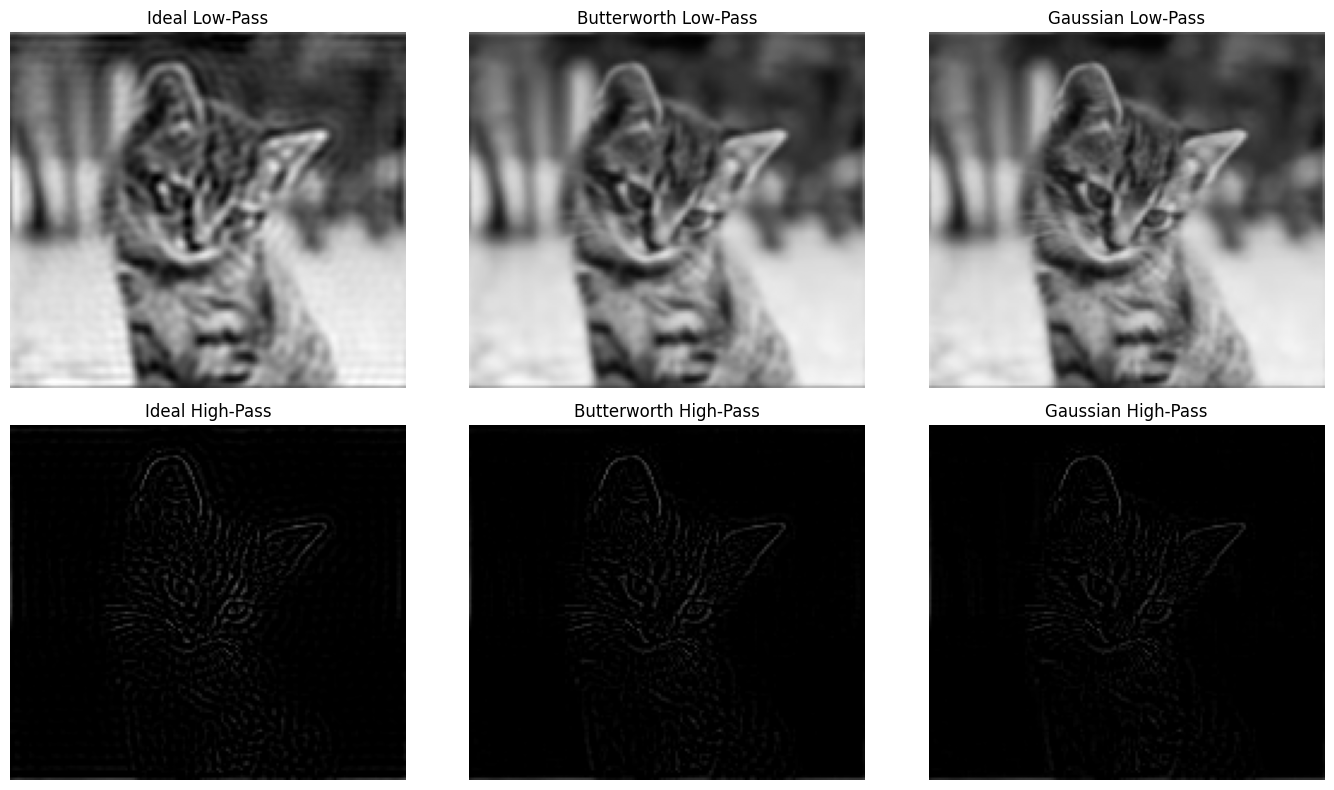

In [14]:
# Compute 2D DFT and distance matrix D(u, v)
dft = np.fft.fftshift(np.fft.fft2(img_gray))
y_coords, x_coords = np.ogrid[:h, :w]
D = np.sqrt((x_coords - w // 2) ** 2 + (y_coords - h // 2) ** 2)

def apply_frequency_filter(spectrum, transfer_function):
    filtered = spectrum * transfer_function
    restored = np.fft.ifft2(np.fft.ifftshift(filtered)).real
    return np.clip(restored, 0, 255).astype(np.uint8)

# Cutoff frequency D0 = 30
D0 = 30
H_ideal_low = (D <= D0).astype(np.float32)
H_butter_low = 1 / (1 + (D / D0) ** 4)
H_gaussian_low = np.exp(-(D ** 2) / (2 * D0 ** 2))

# Apply Low-Pass and High-Pass (1 - H_low) filters
ideal_low_img = apply_frequency_filter(dft, H_ideal_low)
butter_low_img = apply_frequency_filter(dft, H_butter_low)
gaussian_low_img = apply_frequency_filter(dft, H_gaussian_low)

ideal_high_img = apply_frequency_filter(dft, 1 - H_ideal_low)
butter_high_img = apply_frequency_filter(dft, 1 - H_butter_low)
gaussian_high_img = apply_frequency_filter(dft, 1 - H_gaussian_low)

images = [
    ("Ideal Low-Pass", ideal_low_img), ("Butterworth Low-Pass", butter_low_img), ("Gaussian Low-Pass", gaussian_low_img),
    ("Ideal High-Pass", ideal_high_img), ("Butterworth High-Pass", butter_high_img), ("Gaussian High-Pass", gaussian_high_img)
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (title, image) in zip(axes.ravel(), images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 11. Mathematical Morphology
Implement manual Erosion, Dilation, Opening, Closing, and Boundary Extraction on a binary image.

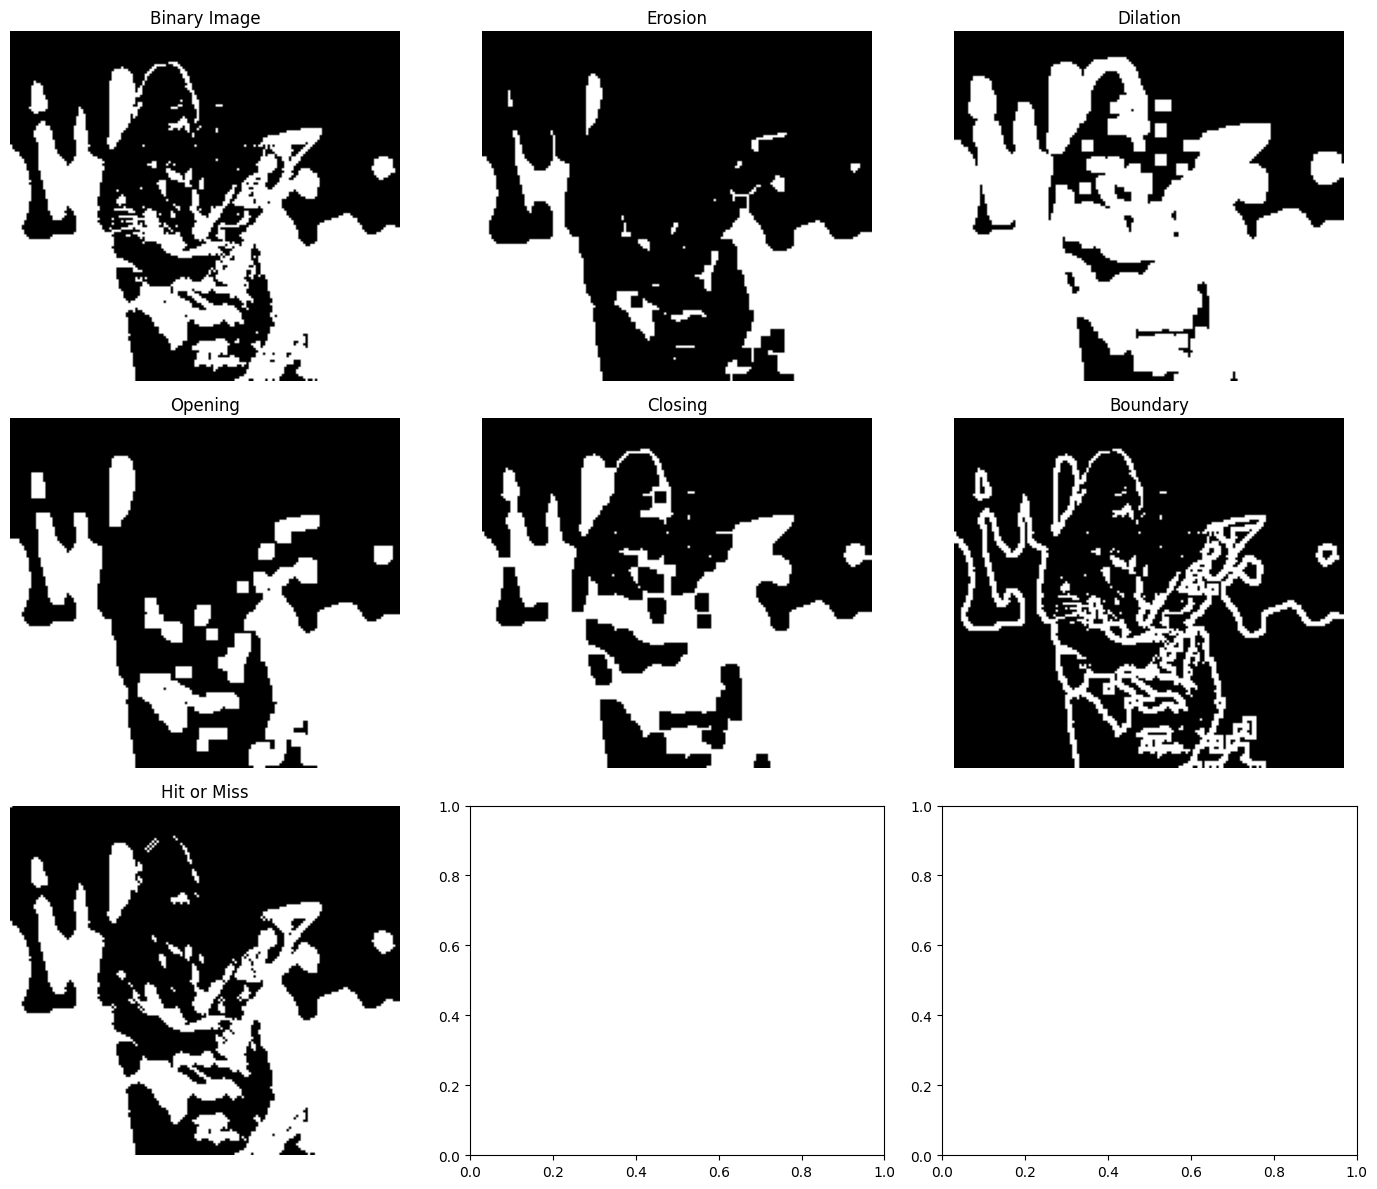

In [30]:
# Manual Erosion and Dilation functions
def erosion(image, structuring_element):
    k_h, k_w = structuring_element.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=255)
    result = np.empty_like(image)

    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            region = padded[row : row + k_h, col : col + k_w]
            result[row, col] = region[structuring_element == 1].min()
    return result


def dilation(image, structuring_element):
    k_h, k_w = structuring_element.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0)
    result = np.empty_like(image)

    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            region = padded[row : row + k_h, col : col + k_w]
            result[row, col] = region[structuring_element == 1].max()
    return result


def opening(image, structuring_element):
    return dilation(erosion(image, structuring_element), structuring_element)


def closing(image, structuring_element):
    return erosion(dilation(image, structuring_element), structuring_element)

# Apply morphological operations with a 5x5 structuring element
kernel = np.ones((5, 5), dtype=np.uint8)
eroded_img = erosion(img_bin, kernel)
dilated_img = dilation(img_bin, kernel)
opened_img = opening(img_bin, kernel)
closed_img = closing(img_bin, kernel)
boundary_img = img_bin - eroded_img  # Manual boundary extraction: A - (A erosion B)



# ── 3. Hit-or-Miss Transform ──────────────────────────────────────────────────
# SE1: foreground pattern (top-left corner detector)
B1 = np.array([[0, 0, 0],
               [0, 1, 1],
               [0, 1, 0]], dtype=np.uint8)
# SE2: background pattern
B2 = np.array([[1, 1, 0],
               [1, 0, 0],
               [0, 0, 0]], dtype=np.uint8)

out1 = erosion(img_bin, B1)
out2 = erosion(img_bin, B2)

hitormiss = cv.bitwise_or(out1,out2)


images = [
    ("Binary Image", img_bin), ("Erosion", eroded_img), ("Dilation", dilated_img),
    ("Opening", opened_img), ("Closing", closed_img), ("Boundary", boundary_img),("Hit or Miss", hitormiss)
]
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for ax, (title, image) in zip(axes.ravel(), images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 12. Edge Detection
Compare manual Prewitt gradient magnitude with Canny edge detection.

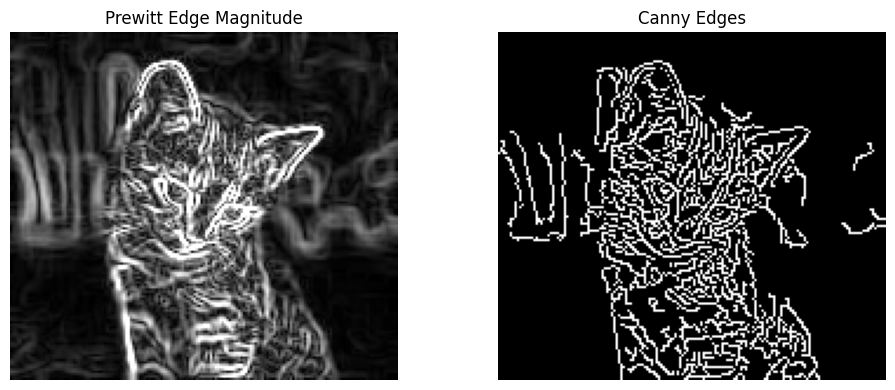

In [16]:
# Prewitt operator using manual apply_kernel
prewitt_kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
prewitt_ky = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
prewitt_x = apply_kernel(prewitt_kx, img_gray)
prewitt_y = apply_kernel(prewitt_ky, img_gray)
prewitt_magnitude = np.clip(np.hypot(prewitt_x, prewitt_y), 0, 255).astype(np.uint8)

# Canny edge detection
canny = cv.Canny(img_gray, 100, 200)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(prewitt_magnitude, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Prewitt Edge Magnitude")
axes[0].axis("off")

axes[1].imshow(canny, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Canny Edges")
axes[1].axis("off")
plt.tight_layout()
plt.show()

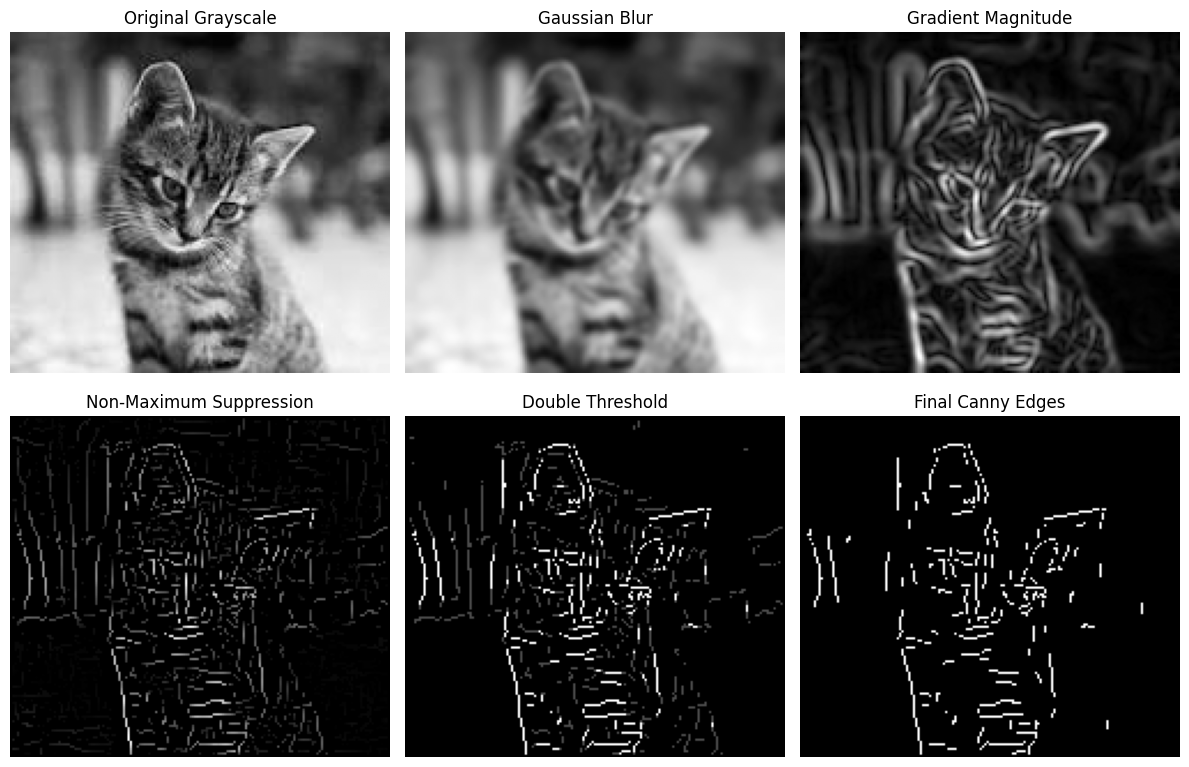

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpeg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 1. Gaussian Blur (Noise Removal)
blur = cv2.GaussianBlur(gray, (5, 5), 1.4)

# 2. Sobel Edge Detection (Gradient Calculation)
Gx = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
Gy = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)

# Calculate Gradient Magnitude
magnitude = np.sqrt(Gx**2 + Gy**2)

# Normalize magnitude to 0-255
magnitude = magnitude / magnitude.max() * 255

# Calculate Gradient Direction
angle = np.arctan2(Gy, Gx) * 180 / np.pi
angle[angle < 0] += 180

# 3. Non-Maximum Suppression
rows, cols = gray.shape
nms = np.zeros((rows, cols), dtype=np.float64)

for i in range(1, rows - 1):
    for j in range(1, cols - 1):

        q = 255
        r = 255

        # Angle 0 degrees
        if (0 <= angle[i, j] < 22.5) or \
           (157.5 <= angle[i, j] <= 180):
            q = magnitude[i, j + 1]
            r = magnitude[i, j - 1]

        # Angle 45 degrees
        elif 22.5 <= angle[i, j] < 67.5:
            q = magnitude[i + 1, j - 1]
            r = magnitude[i - 1, j + 1]

        # Angle 90 degrees
        elif 67.5 <= angle[i, j] < 112.5:
            q = magnitude[i + 1, j]
            r = magnitude[i - 1, j]

        # Angle 135 degrees
        else:
            q = magnitude[i - 1, j - 1]
            r = magnitude[i + 1, j + 1]

        # Keep local maximum
        if magnitude[i, j] >= q and magnitude[i, j] >= r:
            nms[i, j] = magnitude[i, j]

# 4. Double Thresholding
low_threshold = 50
high_threshold = 100

strong = 255
weak = 75

threshold = np.zeros((rows, cols), dtype=np.uint8)

strong_i, strong_j = np.where(nms >= high_threshold)
weak_i, weak_j = np.where(
    (nms >= low_threshold) & (nms < high_threshold)
)

threshold[strong_i, strong_j] = strong
threshold[weak_i, weak_j] = weak

# 5. Edge Tracking by Hysteresis
edges = threshold.copy()

for i in range(1, rows - 1):
    for j in range(1, cols - 1):

        if threshold[i, j] == weak:

            if np.any(
                threshold[i-1:i+2, j-1:j+2] == strong
            ):
                edges[i, j] = strong
            else:
                edges[i, j] = 0

# Remove remaining weak edges
edges[edges != strong] = 0

# 6. Display Results
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Grayscale')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(blur, cmap='gray')
plt.title('Gaussian Blur')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(magnitude, cmap='gray')
plt.title('Gradient Magnitude')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(nms, cmap='gray')
plt.title('Non-Maximum Suppression')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(threshold, cmap='gray')
plt.title('Double Threshold')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(edges, cmap='gray')
plt.title('Final Canny Edges')
plt.axis('off')

plt.tight_layout()
plt.show()